# 01 — Data Preprocessing, EDA and Baseline Models
**Member 1.** Data quality checks, exploratory analysis, the common experimental
protocol, and two reference models: a majority-class baseline and Linear
Discriminant Analysis (LDA).

The protocol itself is implemented in `src/common.py` and imported by every notebook:

| Item | Choice |
|---|---|
| Positive class | malignant = 1 (benign = 0) |
| Train / test split | stratified 80 / 20, `random_state=42` (455 / 114 samples) |
| Model development | 5-fold stratified CV on the training set only, `random_state=42` |
| Metrics | accuracy, precision, malignant recall (sensitivity), specificity, F1, ROC-AUC, confusion matrix |
| Tuning criterion | malignant-class F1 (balances missed cancers against false alarms) |
| Test set | used once, in notebook 07, after all tuning |
| Leakage control | scaling / PCA / feature selection live inside sklearn `Pipeline`s |

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from common import *
from models import build_pipeline, display_name

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 40)

## 1. Data quality

In [2]:
raw = load_raw()
print("shape:", raw.shape)
raw.head()

shape: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("missing values per column (total):", int(raw.isna().sum().sum()))
print("duplicate rows:", int(raw.duplicated().sum()))
print("duplicate rows ignoring id:", int(raw.drop(columns="id").duplicated().sum()))
print("duplicate ids:", int(raw["id"].duplicated().sum()))
print("diagnosis values:", raw["diagnosis"].unique())
print("negative feature values:", int((raw[FEATURE_NAMES] < 0).sum().sum()))
print("dtypes:", raw[FEATURE_NAMES].dtypes.unique())

missing values per column (total): 0
duplicate rows: 0
duplicate rows ignoring id: 0
duplicate ids: 0
diagnosis values: <ArrowStringArray>
['M', 'B']
Length: 2, dtype: str
negative feature values: 0
dtypes: [dtype('float64')]


The data are clean: no missing values, no duplicate records, only `M`/`B` labels and
no negative measurements. A handful of features contain exact zeros
(`concavity_*`, `concave_points_*`) — these are legitimate (nuclei with no concave
segments), not missing values, so they are kept.

In [4]:
zeros = (raw[FEATURE_NAMES] == 0).sum()
zeros[zeros > 0]

concavity_mean          13
concave_points_mean     13
concavity_se            13
concave_points_se       13
concavity_worst         13
concave_points_worst    13
dtype: int64

The `id` column is an identifier with no predictive meaning and is dropped
(`load_data()` returns only the 30 numeric features).

In [5]:
X, y = load_data()
X_train, X_test, y_train, y_test = get_split()
print("X:", X.shape, " train:", X_train.shape, " test:", X_test.shape)

X: (569, 30)  train: (455, 30)  test: (114, 30)


## 2. Class balance

In [6]:
bal = pd.DataFrame({
    "full": y.value_counts(),
    "train": y_train.value_counts(),
    "test": y_test.value_counts(),
}).rename(index={0: "benign", 1: "malignant"})
bal.loc["% malignant"] = (bal.loc["malignant"] / bal.sum() * 100).round(1)
bal

,full,train,test
malignant,,,
benign,357.0,285.0,72.0
malignant,212.0,170.0,42.0
% malignant,37.3,37.4,36.8


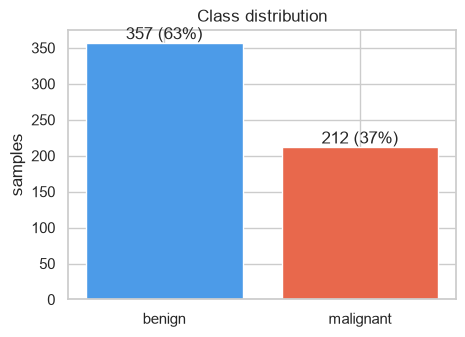

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = y.map({0: "benign", 1: "malignant"}).value_counts()
ax.bar(counts.index, counts.values, color=["#4C9BE8", "#E8684C"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, f"{v} ({v / len(y):.0%})", ha="center")
ax.set_ylabel("samples"); ax.set_title("Class distribution")
savefig(fig, "01_class_distribution"); plt.show()

The classes are moderately imbalanced (≈63 % benign, 37 % malignant). That is why
accuracy alone is not enough and why a majority-class model already scores ≈63 %.
The stratified split keeps the same ratio in train and test.

**From here on, all exploratory analysis uses the training set only**, so nothing we
learn about the data comes from the test set.

## 3. Feature distributions

In [8]:
train = X_train.assign(diagnosis=y_train.map({0: "benign", 1: "malignant"}))
X_train.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
radius_mean,455.0,14.166,3.579,6.981,11.710,13.340,15.935,28.110
texture_mean,455.0,19.418,4.291,9.710,16.335,18.900,21.830,39.280
perimeter_mean,455.0,92.216,24.717,43.790,75.235,86.180,104.500,188.500
area_mean,455.0,659.578,360.419,143.500,420.400,546.400,795.500,2501.000
smoothness_mean,455.0,0.096,0.014,0.063,0.085,0.095,0.105,0.163
compactness_mean,455.0,0.104,0.054,0.019,0.064,0.092,0.130,0.345
concavity_mean,455.0,0.089,0.082,0.000,0.030,0.059,0.132,0.427
concave_points_mean,455.0,0.049,0.040,0.000,0.020,0.033,0.074,0.201
symmetry_mean,455.0,0.181,0.028,0.106,0.162,0.180,0.195,0.304
fractal_dimension_mean,455.0,0.063,0.007,0.050,0.058,0.061,0.066,0.097


Feature scales differ by several orders of magnitude (e.g. `area_worst` up to
~4000 vs `fractal_dimension_se` ≈ 0.003), so standardisation is required for
distance- and margin-based models (KNN, SVM), regularised models (logistic
regression), and PCA.

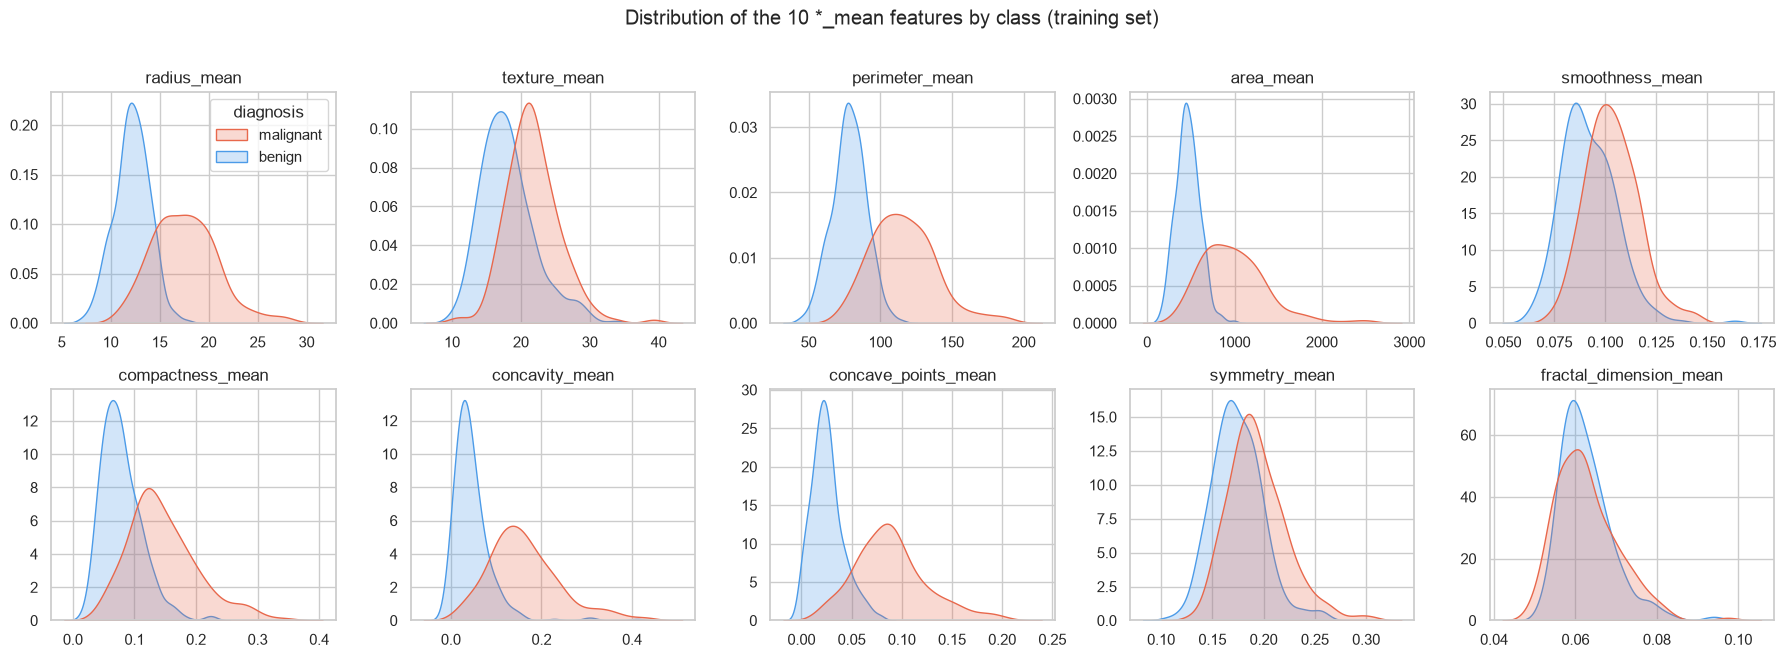

In [9]:
mean_feats = [f for f in FEATURE_NAMES if f.endswith("_mean")]
fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
for ax, f in zip(axes.flat, mean_feats):
    sns.kdeplot(data=train, x=f, hue="diagnosis", fill=True, common_norm=False,
                palette={"benign": "#4C9BE8", "malignant": "#E8684C"}, ax=ax, legend=ax is axes.flat[0])
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Distribution of the 10 *_mean features by class (training set)", y=1.01)
fig.tight_layout(); savefig(fig, "01_mean_feature_kde"); plt.show()

In [10]:
from scipy.stats import skew
sk = X_train.apply(skew).sort_values(ascending=False)
print("Most right-skewed features:\n", sk.head(8).round(2))

Most right-skewed features:
 area_se                 5.48
concavity_se            5.37
fractal_dimension_se    4.07
perimeter_se            3.51
radius_se               3.17
smoothness_se           2.45
symmetry_se             2.24
area_worst              1.90
dtype: float64


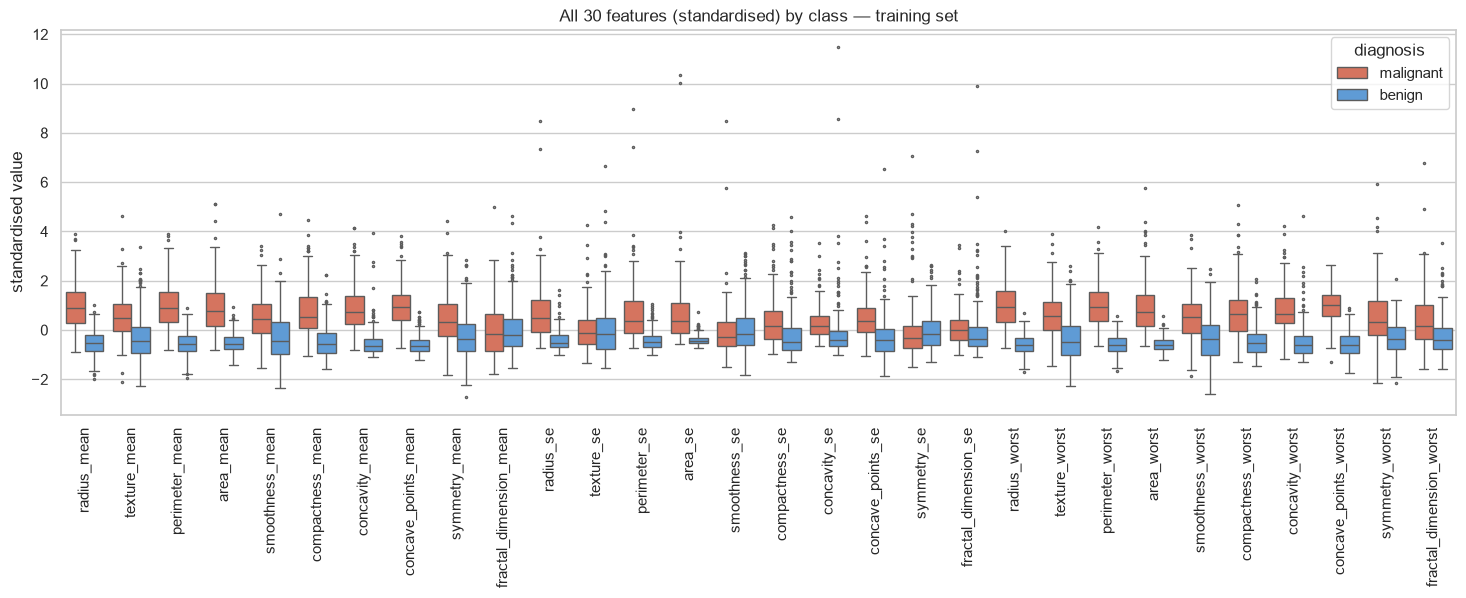

In [11]:
z = (X_train - X_train.mean()) / X_train.std()
long = z.assign(diagnosis=train["diagnosis"]).melt(id_vars="diagnosis", var_name="feature", value_name="z")
fig, ax = plt.subplots(figsize=(18, 5))
sns.boxplot(data=long, x="feature", y="z", hue="diagnosis", fliersize=1.5,
            palette={"benign": "#4C9BE8", "malignant": "#E8684C"}, ax=ax)
ax.tick_params(axis="x", rotation=90); ax.set_ylabel("standardised value"); ax.set_xlabel("")
ax.set_title("All 30 features (standardised) by class — training set")
savefig(fig, "01_boxplots"); plt.show()

**Observations.** Size-related features (radius, perimeter, area) and shape
irregularity (concavity, concave points, compactness) separate the classes strongly —
malignant nuclei are larger and more irregular. Texture separates moderately.
Smoothness, symmetry and fractal dimension (especially their `_se` versions) overlap
heavily and look weakly informative on their own. Many features (area, `_se`
features) are right-skewed with outliers, mostly on the malignant side.

### Univariate separability
Point-biserial correlation with the target and a univariate ROC-AUC for each feature
(computed on the training set).

In [12]:
from sklearn.metrics import roc_auc_score
uni = pd.DataFrame({
    "corr_with_malignant": X_train.corrwith(y_train),
    "univariate_auc": [max(roc_auc_score(y_train, X_train[f]), 1 - roc_auc_score(y_train, X_train[f]))
                       for f in FEATURE_NAMES],
}, index=FEATURE_NAMES).sort_values("univariate_auc", ascending=False)
uni.round(3)

,corr_with_malignant,univariate_auc
perimeter_worst,0.783,0.974
radius_worst,0.778,0.969
area_worst,0.732,0.968
concave_points_mean,0.776,0.964
concave_points_worst,0.786,0.963
perimeter_mean,0.740,0.946
area_mean,0.704,0.937
radius_mean,0.728,0.937
concavity_mean,0.684,0.933
area_se,0.534,0.921


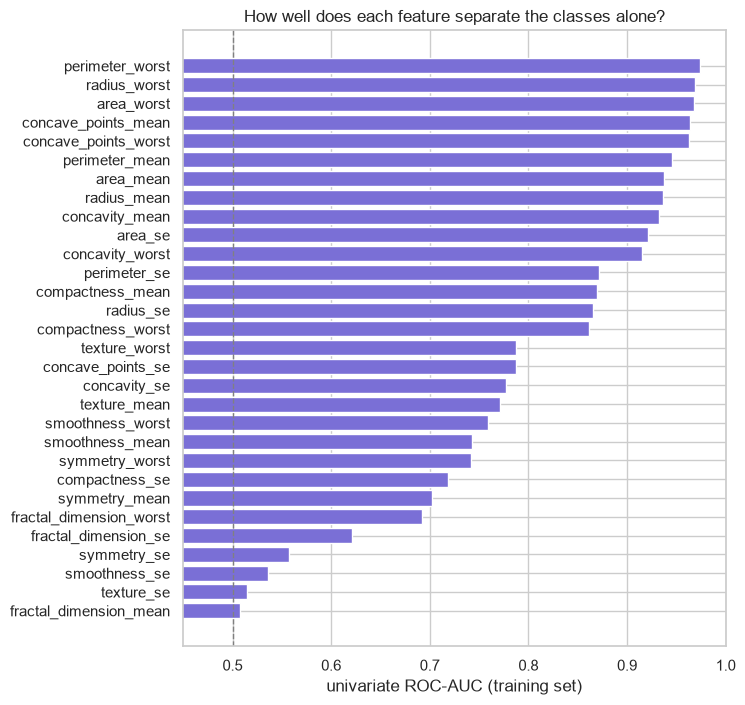

In [13]:
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(uni.index[::-1], uni["univariate_auc"][::-1], color="#7A6FD6")
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_xlim(0.45, 1); ax.set_xlabel("univariate ROC-AUC (training set)")
ax.set_title("How well does each feature separate the classes alone?")
savefig(fig, "01_univariate_auc"); plt.show()

## 4. Correlations between features

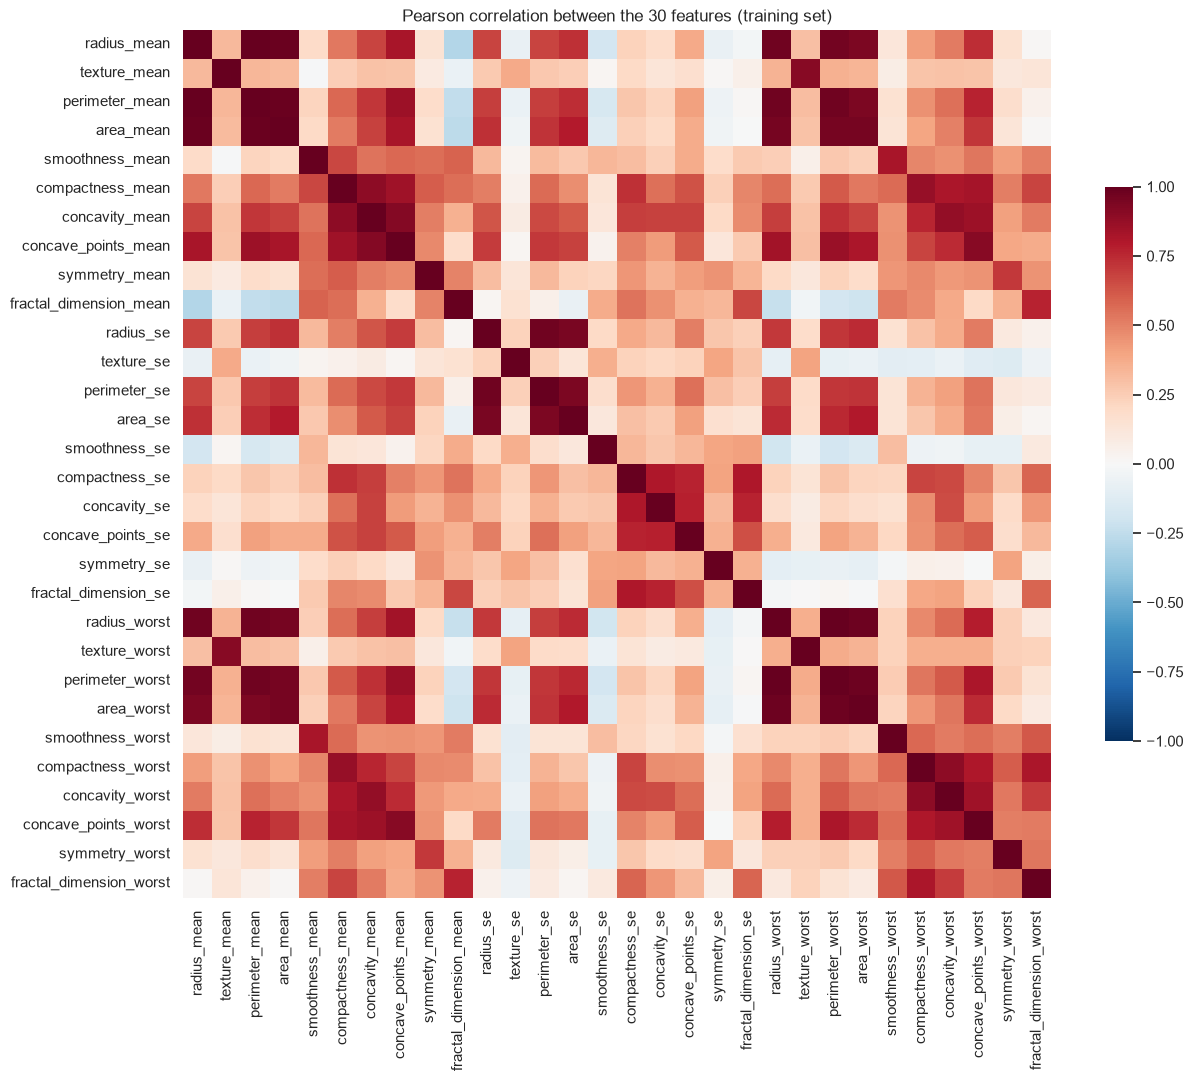

In [14]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"shrink": .6}, ax=ax)
ax.set_title("Pearson correlation between the 30 features (training set)")
savefig(fig, "01_correlation_heatmap"); plt.show()

In [15]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().rename("r").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
pairs["|r|"] = pairs["r"].abs()
high = pairs.sort_values("|r|", ascending=False)
print("pairs with |r| > 0.9:", int((high["|r|"] > 0.9).sum()), "of", len(high))
high.head(15).round(3)

pairs with |r| > 0.9: 21 of 435


,feature_1,feature_2,r,|r|
1,radius_mean,perimeter_mean,0.998,0.998
391,radius_worst,perimeter_worst,0.994,0.994
2,radius_mean,area_mean,0.987,0.987
57,perimeter_mean,area_mean,0.986,0.986
392,radius_worst,area_worst,0.983,0.983
407,perimeter_worst,area_worst,0.977,0.977
246,radius_se,perimeter_se,0.975,0.975
76,perimeter_mean,perimeter_worst,0.970,0.970
74,perimeter_mean,radius_worst,0.969,0.969
19,radius_mean,radius_worst,0.969,0.969


**Strong multicollinearity.** Radius, perimeter and area are almost perfectly
correlated (r > 0.99) because they are geometric functions of each other, and the
`_mean` and `_worst` version of the same measurement are also highly correlated.
21 feature pairs have |r| > 0.9. This redundancy is the main motivation for the
project: the 30 features carry much less than 30 dimensions of independent
information, so PCA (notebook 05) and feature selection (notebook 06) should be able
to compress them substantially.

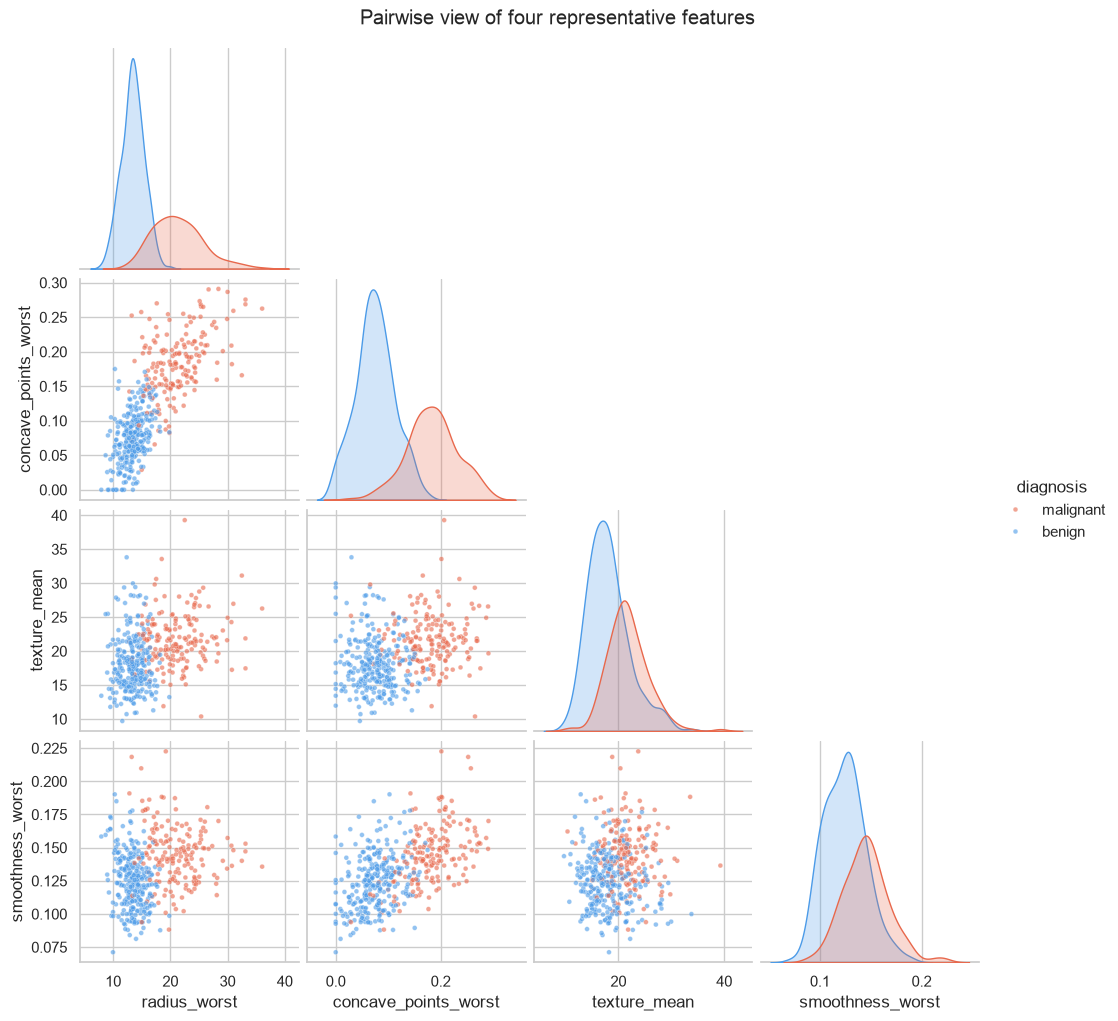

In [16]:
sel = ["radius_worst", "concave_points_worst", "texture_mean", "smoothness_worst"]
g = sns.pairplot(train[sel + ["diagnosis"]], hue="diagnosis", corner=True, plot_kws={"s": 12, "alpha": .6},
                 palette={"benign": "#4C9BE8", "malignant": "#E8684C"})
g.figure.suptitle("Pairwise view of four representative features", y=1.02)
savefig(g.figure, "01_pairplot"); plt.show()

## 5. Baseline models
Both are evaluated with the common 5-fold stratified CV on the training set.
LDA has no hyper-parameters worth tuning here (we use the default SVD solver), so it
serves as a strong, simple linear reference. LDA is reported only in this notebook
(it was listed in both Step 2 and Step 3 of the proposal).

In [17]:
rows = []
for key in ["dummy", "lda"]:
    pipe = build_pipeline(key)
    rows.append(cv_evaluate(pipe, X_train, y_train, name=display_name(key), key=key, feature_set="all 30"))
    save_best_params(key, {})
save_rows(rows, "cv_01_baselines.csv")
summarize(rows)

,model,key,feature_set,accuracy,precision,recall,specificity,f1,roc_auc
0,Majority baseline,dummy,all 30,0.6264 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000
1,LDA,lda,all 30,0.9560 ± 0.0231,0.9935 ± 0.0129,0.8882 ± 0.0600,0.9965 ± 0.0070,0.9369 ± 0.0342,0.9938 ± 0.0041


* The **majority baseline** always predicts *benign*: 62.6 % accuracy but **0 %
  malignant recall** — it misses every cancer. This is the clearest illustration of why
  accuracy alone is misleading here.
* **LDA** already reaches ≈95–96 % accuracy and ROC-AUC ≈ 0.99, so this is an
  "easy" dataset for linear models. Its weak point is malignant recall (≈ 0.89): it
  misses about 1 in 9 malignant tumours in CV. Every model below has to beat LDA to
  be interesting.

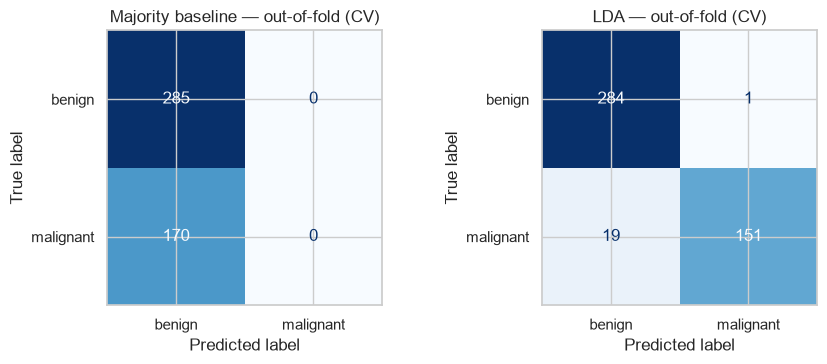

In [18]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, key in zip(axes, ["dummy", "lda"]):
    pred = cross_val_predict(build_pipeline(key), X_train, y_train, cv=get_cv())
    ConfusionMatrixDisplay.from_predictions(y_train, pred, display_labels=CLASS_NAMES, cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{display_name(key)} — out-of-fold (CV)")
fig.tight_layout(); savefig(fig, "01_baseline_confusion"); plt.show()

## Summary
* 569 samples, 30 numeric features, no missing values or duplicates; `id` dropped.
* Moderate imbalance (37 % malignant) → stratified splitting; recall/specificity/F1
  reported alongside accuracy.
* Features are on very different scales and skewed → `StandardScaler` inside every
  pipeline for scale-sensitive models.
* Heavy redundancy (21 pairs with |r| > 0.9) → strong case for PCA / feature selection.
* Reference performance: majority 62.6 % accuracy / 0 recall; LDA ≈ 95–96 % accuracy.